# Problema no homogéneo y principio de Duhamel

Considere

$$
u_{tt}-c^2u_{xx}=F(x,t),\qquad u(x,0)=f(x),\quad u_t(x,0)=g(x).
$$

La solución en la recta es

$$
u(x,t)=\frac{f(x-ct)+f(x+ct)}2
+\frac1{2c}\int_{x-ct}^{x+ct}g(y)\,dy
+\frac1{2c}\int_0^t\int_{x-c(t-s)}^{x+c(t-s)}F(y,s)\,dy\,ds.
$$

La última integral suma respuestas homogéneas producidas en cada instante $s$. Solo influyen los puntos $(y,s)$ del cono pasado: $0\le s\le t$ y $|x-y|\le c(t-s)$.

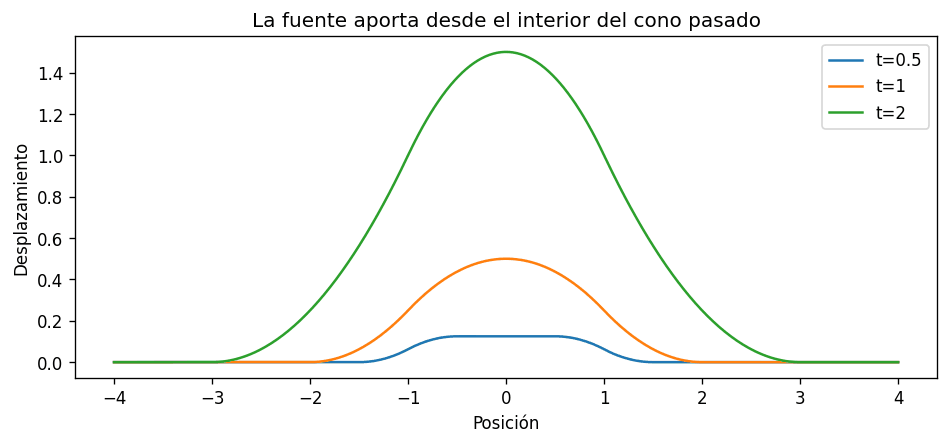

In [1]:
import numpy as np
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8,3.8))
ax.set(xlabel="Posición",ylabel="Desplazamiento")
x=np.linspace(-4,4,400)
for t in [0.5,1,2]:
    # Solución de la onda forzada por F=1 en |x|<1, c=1, datos nulos.
    tau=np.linspace(0,t,320)[:,None]
    longitud=np.maximum(0,np.minimum(x+tau,1)-np.maximum(x-tau,-1))
    ax.plot(x, np.trapezoid(longitud, tau[:,0], axis=0)/2,label=f"t={t:g}")
ax.set_title("La fuente aporta desde el interior del cono pasado")
ax.legend()
fig.tight_layout()
plt.show()

In [ ]:
from manim import *

class DuhamelAcumulaFuentes(Scene):
    def construct(self):
        title = Text("Duhamel: sumar ondas emitidas en cada instante", font_size=34).to_edge(UP)
        axes = Axes(x_range=[-5, 5, 1], y_range=[0, 2.5, 0.5], x_length=10, y_length=4)
        initial = axes.plot(lambda x: 1.8*np.exp(-3*x*x), color=YELLOW)
        label = Text("fuente inicial / referencia", font_size=27).next_to(axes, DOWN)
        self.play(FadeIn(title), Create(axes), Create(initial), FadeIn(label))
        self.wait(4)
        self.play(FadeOut(initial), FadeOut(label))

        waves = VGroup()
        colors = [BLUE, TEAL, GREEN, ORANGE]
        for k, color in enumerate(colors):
            shift = -2.4 + 1.6*k
            graph = axes.plot(
                lambda x, a=shift: 0.55*np.exp(-2.2*(x-a)**2),
                color=color
            )
            waves.add(graph)
            stamp = Text(f"aporte emitido en s={k+1}", font_size=25).next_to(axes, DOWN)
            self.play(Create(graph), FadeIn(stamp), run_time=2)
            self.wait(1)
            self.play(FadeOut(stamp))
        sum_label = Text("la solución es la superposición de todos los aportes", font_size=27).next_to(axes, DOWN)
        self.play(FadeIn(sum_label))
        self.wait(3)

from IPython.display import Video, display

with tempconfig({"pixel_width": 2560, "pixel_height": 1440, "frame_rate": 120,
                 "write_to_movie": True, "format": "mp4", "preview": False}):
    escena = DuhamelAcumulaFuentes()
    escena.render()
    pelicula = escena.renderer.file_writer.movie_file_path
display(Video(str(pelicula), embed=True))


## Ejercicios esenciales

1. Use Duhamel para resolver el problema con $f=g=0$ y $F(x,t)=e^{-t}\cos(kx)$. Reduzca la integral espacial y verifique la ecuación derivando su respuesta.
2. Suponga que $F$ está soportada en $|x|\le a$ y $0\le t\le T$. Describa geométricamente una región donde la respuesta forzada debe ser cero.

**Chequeo conceptual.** El tiempo que aparece en la respuesta homogénea creada en $s$ es $t-s$, no $t$.